In [1]:

# Assignment 4A: CBOW for Document Classification

# Install if required
# !pip install gensim

# 1. Import libraries
import numpy as np
import pandas as pd
import re
import html
import tensorflow as tf

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

Matplotlib is building the font cache; this may take a moment.


In [2]:
#data load
df = pd.read_csv("IMDB Dataset.csv")

#convert sentiment into numerical vals
df['sentiment'] = df['sentiment'].map({
    'positive':1,
    'negative':0
})

In [4]:
#text processing
stop_words = set(ENGLISH_STOP_WORDS)-{"no","not","nor","never"}

def preprocess(text):
    text = html.unescape(text.lower())
    text = re.sub(r"<.*?>", " ", text)
    words = re.findall(r"\b[a-z]+\b", text)

    filtered_words = []
    for word in words:
        if word not in stop_words:
            filtered_words.append(word)

    return filtered_words

In [23]:
#4 Split the dataset
X = df['review']
y = df['sentiment']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#tokenize sentences
train_sentences = []
for review in X_train:
    train_sentences.append(preprocess(review))

test_sentences = []
for review in X_test:
    test_sentences.append(preprocess(review))


In [24]:
#5 train cbow model
word2vec = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window = 5,
    min_count=2,
    sg=0,
    epochs=10
)

In [25]:
#6 convert doc to avg word embeddings
def get_vector(words):
    vectors = []
    for w in words:
        if w in word2vec.wv:
            vectors.append(word2vec.wv[w])

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors,axis=0)

In [26]:
#1
X_train_vec = []
for s in train_sentences:
    X_train_vec.append(get_vector(s))

X_train_vec = np.array(X_train_vec)

#2
X_test_vec = []
for s in test_sentences:
    X_test_vec.append(get_vector(s))

X_test_vec = np.array(X_test_vec)

In [27]:
# 7. Build feed-forward neural network
model = Sequential([
    Input(shape=(100,)),
    Dense(64,activation='relu'),
    Dropout(0.3),
    Dense(32,activation='relu'),
    Dense(1,activation='sigmoid')
])

In [28]:
#compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [29]:
# fit
history = model.fit(
    X_train_vec,y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8257 - loss: 0.3928 - val_accuracy: 0.8627 - val_loss: 0.3216
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8604 - loss: 0.3332 - val_accuracy: 0.8555 - val_loss: 0.3245
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8617 - loss: 0.3260 - val_accuracy: 0.8665 - val_loss: 0.3100
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8657 - loss: 0.3204 - val_accuracy: 0.8685 - val_loss: 0.3073
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8680 - loss: 0.3164 - val_accuracy: 0.8681 - val_loss: 0.3082
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8678 - loss: 0.3130 - val_accuracy: 0.8683 - val_loss: 0.3060
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8710 - loss: 0.3096 - val_accuracy: 0.8673 - val_loss: 0.3060
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8725 - loss: 0.3075 - val_accuracy: 0.

In [30]:
#evaluate the model
loss,accuracy = model.evaluate(X_test_vec,y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8703 - loss: 0.3021
Test Loss: 0.3021063208580017
Test Accuracy: 0.8702999949455261


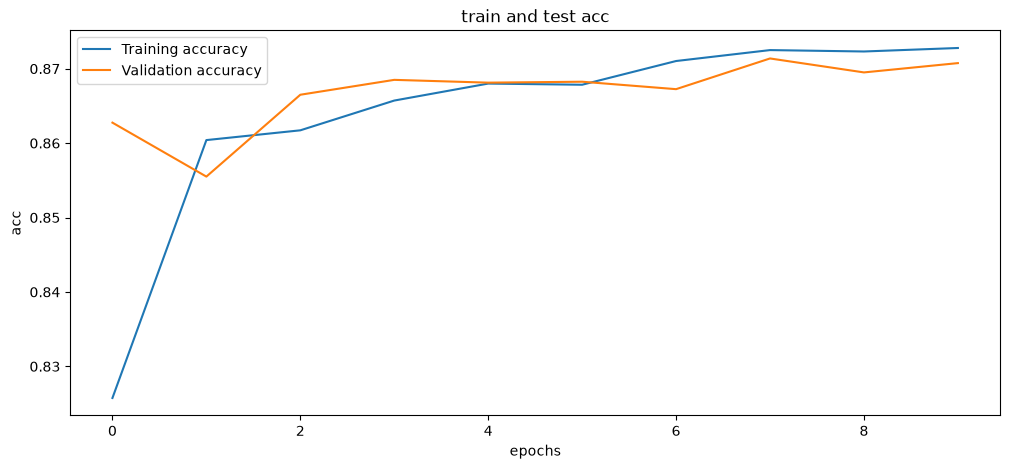

In [33]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))

plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.title('train and test acc')
plt.xlabel('epochs')
plt.ylabel('acc')
plt.legend()
plt.show()